# 04 · Step 0: shared per-question results table (GPU, ~30 min on A100)

Runs every configuration once on the same questions, so Scripts 1 and 2 can be compared fairly and rerun in minutes:

- **16 configurations** = retriever Qwen 3B/7B × answerer Qwen 3B/7B × retrieval samples {1, 3} × answer samples {1, 5}
- **200 dev + 200 test questions**, random and non-overlapping, **20 paragraphs** each (2 gold + 18 BM25 distractors)
- pipeline: retrieve → merge (vote) → answer samples → fuse, with a short-answer line scored by HotpotQA EM/F1

Output: `runs/env_qwen_hotpotqa/<timestamp>_<GPU>/` with `table/per_question.csv` (one row per question × config: answer, EM, F1, tokens, FLOPs, estimated GPU seconds), `table/signals.csv`, `table/configs.csv`, `table/summary.md` (with the **go/no-go check**) and a plot. `status.json` shows live progress; every stage resumes if interrupted (set `RESUME_RUN_DIR`).

**Runtime → Change runtime type → A100 GPU** (G4 also works; L4 is ~2× slower; T4 is refused).

In [8]:
# ==== settings ====
PROJECT_DIR = "/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching"
EXPERIMENT  = "env_qwen_hotpotqa"
LARGE_MODEL_DIR = "Qwen2.5-7B-Instruct"    # or "Qwen2.5-7B-Instruct-AWQ"

DEV_N, TEST_N, N_CANDIDATES, DATA_SEED = 200, 200, 20, 42   # 40/100 took 20 min on an A100; 200/200 is estimated ~30 min
TIME_LIMIT_MIN = 55          # every stage stops cleanly at this limit and keeps what is done
RESUME_RUN_DIR = None        # an interrupted run folder, to continue it
DRY_RUN = False              # True = fake models on CPU, tests the whole notebook in ~1 min

In [9]:
import subprocess, sys, os, json, shutil, time
gpu = subprocess.run("nvidia-smi --query-gpu=name,memory.total,compute_cap --format=csv,noheader 2>/dev/null",
                     shell=True, capture_output=True, text=True).stdout.strip()
print("GPU:", gpu or "none")
if not DRY_RUN:
    assert gpu, "No GPU: Runtime -> Change runtime type -> A100 GPU (or set DRY_RUN = True)."
    if "T4" in gpu:
        raise SystemExit("This runtime has a T4, which cannot run this: the 7B model alone (15 GB) does not fit in its memory.\n"
                         "Runtime -> Change runtime type -> A100 GPU (or G4 / L4) -> Save, then run all cells again.")
    if "A100" not in gpu and "G4" not in gpu and "RTX PRO 6000" not in gpu:
        print("Note: planned for an A100 or G4; this GPU works but timings will differ.")
GPU_TAG = "cpu" if not gpu else gpu.split(",")[0].replace("NVIDIA", "").replace("Tesla", "").strip().split()[0].split("-")[0]
T_START = time.time()

GPU: NVIDIA A100-SXM4-40GB, 40960 MiB, 8.0


In [10]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
from datetime import datetime
from zoneinfo import ZoneInfo
if RESUME_RUN_DIR:
    RUN_DIR = RESUME_RUN_DIR
else:
    stamp = datetime.now(ZoneInfo("Asia/Singapore")).strftime("%Y%m%d-%H%M%S")
    RUN_DIR = f"{PROJECT_DIR}/runs/{EXPERIMENT}/{stamp}_{GPU_TAG}" + ("_dryrun" if DRY_RUN else "")
for sub in ["logs", "code"]:
    os.makedirs(f"{RUN_DIR}/{sub}", exist_ok=True)
print("Run folder:", RUN_DIR)
DATA_DIR = f"{PROJECT_DIR}/data/hotpotqa_q/dev{DEV_N}_test{TEST_N}_c{N_CANDIDATES}_s{DATA_SEED}"
json.dump({"experiment": EXPERIMENT, "data_dir": DATA_DIR, "large_model_dir": LARGE_MODEL_DIR, "gpu": gpu,
           "dev_n": DEV_N, "test_n": TEST_N, "n_candidates": N_CANDIDATES, "data_seed": DATA_SEED, "dry_run": DRY_RUN,
           "started": datetime.now(ZoneInfo("Asia/Singapore")).isoformat()}, open(f"{RUN_DIR}/config.json", "w"), indent=1)

Run folder: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/env_qwen_hotpotqa/20260928-155333_A100


In [12]:
BACKEND = "mock" if DRY_RUN else "vllm"
CODE = "/content/ssw.py"
shutil.copy(f"{PROJECT_DIR}/code/ssw.py", CODE)
shutil.copy(CODE, f"{RUN_DIR}/code/ssw.py")          # keep the exact code with the results

def minutes_left():
    return max(1.0, TIME_LIMIT_MIN - (time.time() - T_START) / 60)

def run_stage(args, log_name):
    """Runs one ssw.py command in a fresh process; streams output here and into logs/<log_name>."""
    cmd = [sys.executable, "-u", CODE] + [str(a) for a in args]
    t0 = time.time()
    with open(f"{RUN_DIR}/logs/{log_name}", "a") as log:
        log.write("\n$ " + " ".join(cmd) + "\n")
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
        for line in p.stdout:
            log.write(line)
            if any(k in line for k in ("it/s]", "s/it]", "INFO ", "(EngineCore")):
                continue                      # keep the notebook readable; everything is in the log file
            print(line, end="")
        p.wait()
    TIMES[log_name.replace(".log", "")] = round(time.time() - t0)
    json.dump(TIMES, open(f"{RUN_DIR}/logs/stage_times.json", "w"), indent=1)
    print(f"--- {log_name}: exit {p.returncode}, {time.time() - t0:.0f}s, {minutes_left():.0f} min left of the limit")
    if p.returncode != 0:
        raise RuntimeError(f"stage failed - see {RUN_DIR}/logs/{log_name}")
TIMES = {}

### Data: random dev/test samples (CPU, <1 min, built once and reused)

In [13]:
if not os.path.exists(f"{DATA_DIR}/test.json"):
    run_stage(["build_data", "--hotpot_dev", f"{PROJECT_DIR}/AgentTTS/data/HotpotQA/hotpotqa-dev.json", "--out_dir", DATA_DIR,
               "--dev_n", DEV_N, "--test_n", TEST_N, "--n_candidates", N_CANDIDATES, "--seed", DATA_SEED], "00_build_data.log")
else:
    print("using existing data in", DATA_DIR)

[07:53:36] HotpotQA dev: 7405 questions, 66609 paragraphs; building BM25 ...
[07:53:43] wrote /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/data/hotpotqa_q/dev200_test200_c20_s42/dev.json: 200 questions x 20 paragraphs (~2590 tokens of paragraphs each)
[07:53:43] wrote /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/data/hotpotqa_q/dev200_test200_c20_s42/test.json: 200 questions x 20 paragraphs (~2619 tokens of paragraphs each)
--- 00_build_data.log: exit 0, 10s, 55 min left of the limit


In [14]:
# vLLM runs only inside the stage processes, so no runtime restart is needed (~3-5 min)
if not DRY_RUN:
    !pip install -q vllm
    !pip uninstall -y -q torchaudio   # Colab's torchaudio is built for another CUDA version and breaks imports
    chk = subprocess.run([sys.executable, "-c", "from vllm import LLM; import vllm, torch; print('vLLM', vllm.__version__, '| torch', torch.__version__)"],
                         capture_output=True, text=True)
    print(chk.stdout or chk.stderr[-2000:])
    assert chk.returncode == 0, "vLLM does not import - Runtime -> Disconnect and delete runtime, then run again."
TIMES["install_vllm"] = round(time.time() - T_START)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 314.9/314.9 MB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 110.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.7/211.7 kB 22.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 124.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.7/322.7 kB 33.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.0/111.0 kB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.4/45.4 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 129.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 782.6/782.6 kB 57.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 109.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.2/43.2 MB 58.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 729.6/729.6 kB 53.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 

In [15]:
LOCAL = "/content/models"
MODELS = {
    "S": {"id": "Qwen/Qwen2.5-3B-Instruct", "dir": "Qwen2.5-3B-Instruct", "params": 3.09e9, "nominal": 3e9},
    "L": {"id": "Qwen/Qwen2.5-7B-Instruct", "dir": LARGE_MODEL_DIR,       "params": 7.62e9, "nominal": 7e9},
}
_t = time.time()
for key in ["S", "L"]:
    m = MODELS[key] if key in MODELS else {"dir": key}
    src, dst = f"{PROJECT_DIR}/models/{m['dir']}", f"{LOCAL}/{m['dir']}"
    m["path"] = dst
    if DRY_RUN:
        continue
    assert os.path.exists(f"{src}/config.json"), f"{src} missing - run 00_setup_download_qwen7b first."
    if not os.path.exists(f"{dst}/config.json"):
        print("copying", m["dir"], "to local disk ...")
        shutil.copytree(src, dst, dirs_exist_ok=True)
for m in MODELS.values():
    m["path"] = f"{LOCAL}/{m['dir']}"
json.dump(MODELS, open(f"{RUN_DIR}/models.json", "w"), indent=1)
TIMES["copy_models"] = round(time.time() - _t)
print(f"models ready in {time.time() - _t:.0f}s")

copying Qwen2.5-3B-Instruct to local disk ...
copying Qwen2.5-7B-Instruct to local disk ...
models ready in 379s


### Retrieval (3 samples per question) with 3B, then 7B

In [16]:
COMMON = ["--run_dir", RUN_DIR, "--data_dir", DATA_DIR, "--models_json", f"{RUN_DIR}/models.json", "--backend", BACKEND]
for k in ["S", "L"]:
    run_stage(["retrieve", "--model_key", k, "--time_limit_min", minutes_left()] + COMMON, f"01_retrieve_{k}.log")

[08:03:44] retrieve | Qwen/Qwen2.5-3B-Instruct | 400 questions (0 already done) | 3 samples
[08:07:41]   20/400
[08:07:47]   40/400
[08:07:53]   60/400
[08:07:59]   80/400
[08:08:04]   100/400
[08:08:09]   120/400
[08:08:13]   140/400
[08:08:19]   160/400
[08:08:25]   180/400
[08:08:31]   200/400
[08:08:37]   220/400
[08:08:41]   240/400
[08:08:46]   260/400
[08:08:51]   280/400
[08:08:56]   300/400
[08:09:01]   320/400
[08:09:06]   340/400
[08:09:12]   360/400
[08:09:17]   380/400
[08:09:22]   400/400
[08:09:22] retrieve done: 123s generation + 215s load
--- 01_retrieve_S.log: exit 0, 342s, 39 min left of the limit
[08:09:26] retrieve | Qwen/Qwen2.5-7B-Instruct | 400 questions (0 already done) | 3 samples
[08:11:07]   20/400
[08:11:19]   40/400
[08:11:29]   60/400
[08:11:40]   80/400
[08:11:51]   100/400
[08:12:02]   120/400
[08:12:12]   140/400
[08:12:23]   160/400
[08:12:33]   180/400
[08:12:44]   200/400
[08:12:55]   220/400
[08:13:06]   240/400
[08:13:17]   260/400
[08:13:28]   28

### Answer (5 samples) + fuse, with 7B then 3B, on both retrievers' selections

In [17]:
for k in ["L", "S"]:
    run_stage(["answer", "--model_key", k, "--time_limit_min", minutes_left()] + COMMON, f"02_answer_{k}.log")

[08:14:36] answer | Qwen/Qwen2.5-7B-Instruct | retrievers ['L', 'S'] | 400 questions (0 done) | 5 answer samples + fusion
[08:15:52]   20/400 | answer prompts 39, fuser prompts 78
[08:16:01]   40/400 | answer prompts 44, fuser prompts 88
[08:16:07]   60/400 | answer prompts 43, fuser prompts 86
[08:16:13]   80/400 | answer prompts 40, fuser prompts 80
[08:16:18]   100/400 | answer prompts 39, fuser prompts 78
[08:16:27]   120/400 | answer prompts 39, fuser prompts 78
[08:16:32]   140/400 | answer prompts 42, fuser prompts 84
[08:16:42]   160/400 | answer prompts 42, fuser prompts 84
[08:16:48]   180/400 | answer prompts 41, fuser prompts 82
[08:16:57]   200/400 | answer prompts 37, fuser prompts 74
[08:17:05]   220/400 | answer prompts 46, fuser prompts 92
[08:17:13]   240/400 | answer prompts 42, fuser prompts 84
[08:17:19]   260/400 | answer prompts 42, fuser prompts 84
[08:17:25]   280/400 | answer prompts 42, fuser prompts 84
[08:17:31]   300/400 | answer prompts 39, fuser prompts 

### Table, costs, signals and the go/no-go check

In [18]:
run_stage(["table", "--run_dir", RUN_DIR, "--data_dir", DATA_DIR, "--models_json", f"{RUN_DIR}/models.json"], "03_table.log")
print("\nSTEP0_RUN_DIR for notebooks 05 and 06:\n", RUN_DIR)

# Step 0 summary - 20260928-155333_A100

GPU: NVIDIA A100-SXM4-40GB, 8.0 · configs: 16 · questions: {'dev': 200, 'test': 200}

Measured lengths used for Eq. 4: retrieval Np=2748, Nd=150; QA Np=351, Nd=22


## dev: configurations (mean per question)

| config | meaning | EM | F1 | Ret_F1 | TFLOPs/q | est. GPU s/q | Eq.4 budget |
|---|---|---|---|---|---|---|---|
| L3-L5 | retrieval 7B x3, answer 7B x5 | 0.460 | 0.597 | 0.729 | 63.7 | 0.71 | 129 |
| L1-L5 | retrieval 7B x1, answer 7B x5 | 0.455 | 0.591 | 0.736 | 57.6 | 0.64 | 118 |
| L3-L1 | retrieval 7B x3, answer 7B x1 | 0.395 | 0.497 | 0.729 | 61.6 | 0.69 | 126 |
| L1-L1 | retrieval 7B x1, answer 7B x1 | 0.390 | 0.494 | 0.736 | 55.6 | 0.62 | 115 |
| L3-S5 | retrieval 7B x3, answer 3B x5 | 0.370 | 0.497 | 0.729 | 55.8 | 0.66 | 120 |
| L1-S5 | retrieval 7B x1, answer 3B x5 | 0.370 | 0.494 | 0.736 | 49.8 | 0.60 | 109 |
| S3-L5 | retrieval 3B x3, answer 7B x5 | 0.370 | 0.478 | 0.512 | 32.9 | 0.45 | 63 |
| S1-L5 | retrieval 3B x1, answer 7

# Step 0 summary - 20260928-155333_A100

GPU: NVIDIA A100-SXM4-40GB, 8.0 · configs: 16 · questions: {'dev': 200, 'test': 200}

Measured lengths used for Eq. 4: retrieval Np=2748, Nd=150; QA Np=351, Nd=22


## dev: configurations (mean per question)

| config | meaning | EM | F1 | Ret_F1 | TFLOPs/q | est. GPU s/q | Eq.4 budget |
|---|---|---|---|---|---|---|---|
| L3-L5 | retrieval 7B x3, answer 7B x5 | 0.460 | 0.597 | 0.729 | 63.7 | 0.71 | 129 |
| L1-L5 | retrieval 7B x1, answer 7B x5 | 0.455 | 0.591 | 0.736 | 57.6 | 0.64 | 118 |
| L3-L1 | retrieval 7B x3, answer 7B x1 | 0.395 | 0.497 | 0.729 | 61.6 | 0.69 | 126 |
| L1-L1 | retrieval 7B x1, answer 7B x1 | 0.390 | 0.494 | 0.736 | 55.6 | 0.62 | 115 |
| L3-S5 | retrieval 7B x3, answer 3B x5 | 0.370 | 0.497 | 0.729 | 55.8 | 0.66 | 120 |
| L1-S5 | retrieval 7B x1, answer 3B x5 | 0.370 | 0.494 | 0.736 | 49.8 | 0.60 | 109 |
| S3-L5 | retrieval 3B x3, answer 7B x5 | 0.370 | 0.478 | 0.512 | 32.9 | 0.45 | 63 |
| S1-L5 | retrieval 3B x1, answer 7B x5 | 0.370 | 0.493 | 0.520 | 31.6 | 0.43 | 58 |
| S3-L1 | retrieval 3B x3, answer 7B x1 | 0.340 | 0.423 | 0.512 | 29.9 | 0.42 | 60 |
| S1-L1 | retrieval 3B x1, answer 7B x1 | 0.335 | 0.426 | 0.520 | 28.6 | 0.40 | 55 |
| S3-S5 | retrieval 3B x3, answer 3B x5 | 0.300 | 0.394 | 0.512 | 24.5 | 0.40 | 53 |
| L3-S1 | retrieval 7B x3, answer 3B x1 | 0.280 | 0.364 | 0.729 | 55.0 | 0.65 | 118 |
| S1-S5 | retrieval 3B x1, answer 3B x5 | 0.280 | 0.398 | 0.520 | 23.2 | 0.38 | 48 |
| L1-S1 | retrieval 7B x1, answer 3B x1 | 0.275 | 0.355 | 0.736 | 49.1 | 0.58 | 107 |
| S3-S1 | retrieval 3B x3, answer 3B x1 | 0.225 | 0.287 | 0.512 | 23.4 | 0.38 | 52 |
| S1-S1 | retrieval 3B x1, answer 3B x1 | 0.210 | 0.282 | 0.520 | 22.1 | 0.36 | 47 |

**Oracle router (dev):** EM 0.590 at 27.7 TFLOPs/q · best single config L3-L5: EM 0.460 at 63.7 TFLOPs/q · cheapest S1-S1: EM 0.210 at 22.1 TFLOPs/q

Questions only a config using the 7B gets right: 53 of 200 · only all-3B gets right: 0

**Go/no-go:** on dev the oracle router is +0.130 EM vs the best single config, at 57% less compute. There is room for per-question switching - go ahead with Script 2.

## test: configurations (mean per question)

| config | meaning | EM | F1 | Ret_F1 | TFLOPs/q | est. GPU s/q | Eq.4 budget |
|---|---|---|---|---|---|---|---|
| L1-L5 | retrieval 7B x1, answer 7B x5 | 0.545 | 0.660 | 0.708 | 58.4 | 0.65 | 118 |
| L3-L5 | retrieval 7B x3, answer 7B x5 | 0.545 | 0.659 | 0.720 | 64.1 | 0.71 | 129 |
| L1-L1 | retrieval 7B x1, answer 7B x1 | 0.470 | 0.563 | 0.708 | 56.1 | 0.62 | 115 |
| L3-L1 | retrieval 7B x3, answer 7B x1 | 0.465 | 0.554 | 0.720 | 62.0 | 0.69 | 126 |
| S3-L5 | retrieval 3B x3, answer 7B x5 | 0.440 | 0.531 | 0.502 | 33.2 | 0.45 | 63 |
| S1-L5 | retrieval 3B x1, answer 7B x5 | 0.420 | 0.514 | 0.498 | 32.1 | 0.43 | 58 |
| S3-L1 | retrieval 3B x3, answer 7B x1 | 0.405 | 0.481 | 0.502 | 29.9 | 0.42 | 60 |
| L3-S5 | retrieval 7B x3, answer 3B x5 | 0.400 | 0.518 | 0.720 | 56.3 | 0.67 | 120 |
| L1-S5 | retrieval 7B x1, answer 3B x5 | 0.400 | 0.524 | 0.708 | 50.5 | 0.61 | 109 |
| S1-L1 | retrieval 3B x1, answer 7B x1 | 0.395 | 0.480 | 0.498 | 28.7 | 0.40 | 55 |
| L1-S1 | retrieval 7B x1, answer 3B x1 | 0.345 | 0.447 | 0.708 | 49.6 | 0.59 | 107 |
| L3-S1 | retrieval 7B x3, answer 3B x1 | 0.335 | 0.439 | 0.720 | 55.5 | 0.66 | 118 |
| S3-S5 | retrieval 3B x3, answer 3B x5 | 0.300 | 0.416 | 0.502 | 24.6 | 0.40 | 53 |
| S1-S5 | retrieval 3B x1, answer 3B x5 | 0.270 | 0.387 | 0.498 | 23.4 | 0.38 | 48 |
| S3-S1 | retrieval 3B x3, answer 3B x1 | 0.270 | 0.345 | 0.502 | 23.5 | 0.39 | 52 |
| S1-S1 | retrieval 3B x1, answer 3B x1 | 0.250 | 0.337 | 0.498 | 22.2 | 0.36 | 47 |

**Oracle router (test):** EM 0.660 at 28.2 TFLOPs/q · best single config L1-L5: EM 0.545 at 58.4 TFLOPs/q · cheapest S1-S1: EM 0.250 at 22.2 TFLOPs/q

Questions only a config using the 7B gets right: 60 of 200 · only all-3B gets right: 1


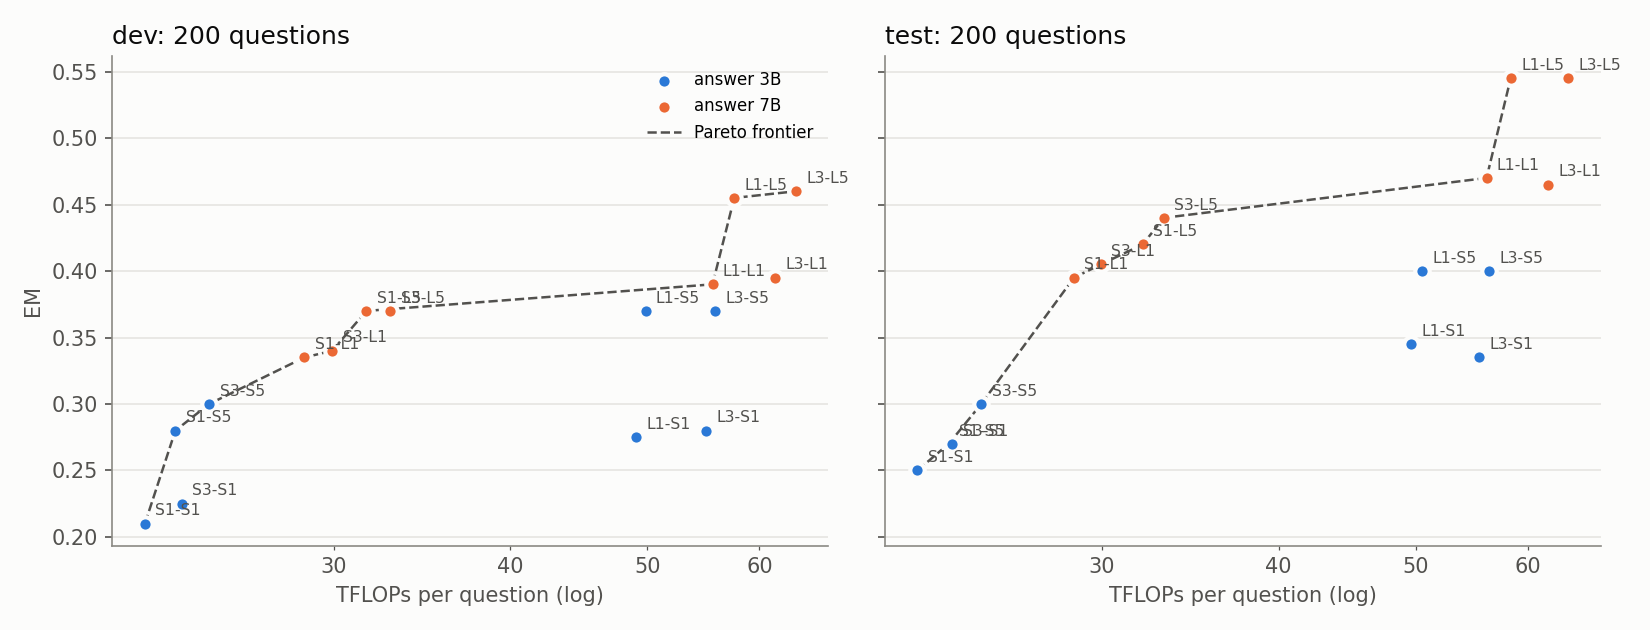

Wall-clock (s): {'00_build_data': 10, 'install_vllm': 233, 'copy_models': 379, '01_retrieve_S': 342, '01_retrieve_L': 310, '02_answer_L': 215, '02_answer_S': 159, '03_table': 2, 'total_notebook': 1641}


In [19]:
from IPython.display import Image, Markdown, display
for f in ["table/summary.md", "table/configs_em_vs_flops.png"]:
    p = f"{RUN_DIR}/{f}"
    if not os.path.exists(p):
        continue
    display(Markdown(open(p).read()) if p.endswith(".md") else Image(p))
TIMES["total_notebook"] = round(time.time() - T_START)
json.dump(TIMES, open(f"{RUN_DIR}/logs/stage_times.json", "w"), indent=1)
print("Wall-clock (s):", TIMES)